# 03 · U3 cuRobo rollout — 상태 예측과 비용 계산

**한 줄 요약 (노션 U3):** 400×30×7 가속도 후보를 미래 관절 상태와 충돌 구 위치로 바꾸고, 목표·한계·충돌 비용으로 각 trajectory를 평가한다.

### 학습 목표
1. 가변 dt horizon을 cuRobo 식으로 계산하고, 노션의 0.75 s와 최종 실험의 0.675 s가 왜 다른지 확인한다.
2. 가속도 → 관절 위치·속도 적분을 7관절로 확장한다.
3. cuRobo로 Franka FK를 돌려 충돌 구(활성 61개)와 buffer 20 mm를 직접 본다.
4. **Isaac Sim 없이** cuRobo `MpcSolver`를 만들고, R 실험 로그의 실제 관절 상태에서 `act_seq[400,30,7] → spheres → costs[400,30]`을 들여다본다.
5. activation distance η 비용식을 그리고 노션의 숫자 표를 재현한다.

### 노션 정리와의 연결
| 노션 U3 기록 | 이 노트 |
|---|---|
| 입력 `act_seq[400,30,7]` → 출력 `costs[400,30]` | 4절에서 cuRobo로 실제 shape 확인 |
| 포함: 가속도 적분·FK·구 위치 / 미포함: rigid-body dynamics | 2·3절 |
| horizon 30 step ≈ 0.75 s (0.02 s 기준) | 1절: 최종 replay는 `--model-dt 1/60` → **0.675 s** |
| 비용 구성 표 (pose [60,300,20,20], bound 5000, self 50000, env 100000…) | 6절 (yml 직접 로드) |
| 61개 sphere, buffer 0.004 → 0.02 override | 3절 |
| η 비용식, 숫자 예시 표 | 5절 |
| MPC dt 0.02 vs physics dt 0.0167 (비율 1.2) | 1절: 최종 실험은 둘 다 1/60 |

**실행 환경:** 4절은 cuRobo와 CUDA GPU가 필요하다. Isaac Sim 파이썬(`python.sh`) 커널에서 `PYTHONPATH=~/curobo/src`로 실행한다 (00 노트북의 커널 설정 참고). cuRobo가 없으면 해당 셀만 건너뛴다.

In [1]:
import time
import numpy as np
from common import *
plt = setup_plot()
try:
    import torch
    import curobo
    HAS_CUROBO = torch.cuda.is_available()
except ImportError:
    HAS_CUROBO = False
print('cuRobo + CUDA 사용 가능:', HAS_CUROBO)

cuRobo + CUDA 사용 가능: True


## 1. 가변 dt horizon

`particle_mpc.yml`의 `dt_traj_params: {base_dt: 0.01, base_ratio: 0.5, max_dt: 0.04}`이고, solver를 만들 때 `step_dt`가 `base_dt`를 덮어쓴다. 앞 절반은 `base_dt`로 고정하고, 뒤 절반은 `base_dt → max_dt`로 선형 증가시킨다 (`kinematic_model.py:42` `get_dt_array`, `common.dt_array`로 옮김).

- `scene.json`의 `solver_dt = 0.02` → 0.3 + 15×(0.02+0.04)/2 = **0.75 s** (노션 기록)
- 최종 replay `--model-dt 0.016666…` → 0.25 + 15×(0.0167+0.04)/2 = **0.675 s**

아래에서 계산값을 R/LOW/HIGH의 `control-settings.json`에 기록된 실제 `trajectory_dt`와 비교한다.

base_dt=0.0200: 앞 15칸 합 0.300 s, 뒤 15칸 합 0.450 s, 전체 0.750 s
base_dt=0.0167: 앞 15칸 합 0.250 s, 뒤 15칸 합 0.425 s, 전체 0.675 s

로그 model_base_dt = 0.016667, physics_dt = 0.016667
로그 trajectory_duration_s = 0.6750
계산값과 로그 trajectory_dt 최대 차이: 1.99e-09


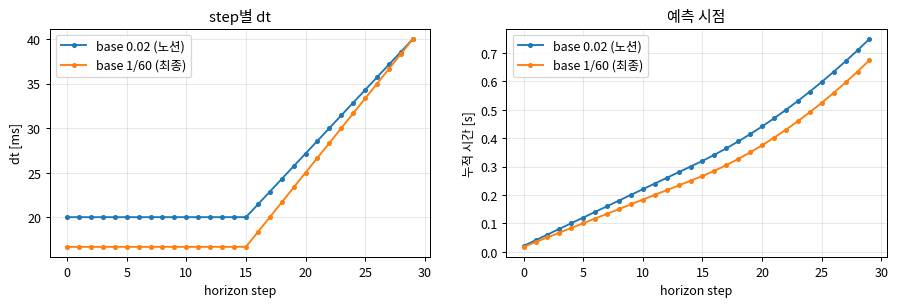

In [2]:
for base in [0.02, 1 / 60]:
    d = dt_array(base)
    print('base_dt=%.4f: 앞 15칸 합 %.3f s, 뒤 15칸 합 %.3f s, 전체 %.3f s' % (base, d[:15].sum(), d[15:].sum(), d.sum()))

logged = json.loads((EVIDENCE / 'HIGH' / 'control-settings.json').read_text())
print('\n로그 model_base_dt = %.6f, physics_dt = %.6f' % (logged['model_base_dt'], logged['physics_dt']))
print('로그 trajectory_duration_s = %.4f' % logged['trajectory_duration_s'])
print('계산값과 로그 trajectory_dt 최대 차이: %.2e' % np.abs(dt_array(1 / 60) - np.array(logged['trajectory_dt'])).max())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
for base, lab in [(0.02, 'base 0.02 (노션)'), (1 / 60, 'base 1/60 (최종)')]:
    d = dt_array(base)
    axs[0].plot(d * 1000, 'o-', ms=3, label=lab)
    axs[1].plot(np.cumsum(d), 'o-', ms=3, label=lab)
axs[0].set_xlabel('horizon step'); axs[0].set_ylabel('dt [ms]'); axs[0].legend(); axs[0].set_title('step별 dt')
axs[1].set_xlabel('horizon step'); axs[1].set_ylabel('누적 시간 [s]'); axs[1].legend(); axs[1].set_title('예측 시점')
plt.show()

**의미:** 가까운 미래는 촘촘하게, 먼 미래는 성기게 본다. 같은 30칸으로 더 먼 미래까지 보면서 바로 실행할 앞부분의 정밀도는 유지한다.

노션에 남긴 "MPC 적분 dt 0.02 vs physics dt 1/60, 비율 약 1.2" 문제는 최종 replay에서 `--model-dt 1/60`으로 두 dt를 같게 맞춰 해소했다 (`hand_experiment.py:100` `step_dt=... args.model_dt`).

## 2. 가속도 적분 — 7관절로 확장

01·02의 점질량과 같은 구조를 관절 7개에 적용한다. 각 관절이 독립된 이중 적분기이고, dt만 step마다 다르다. cuRobo는 이 적분을 CUDA 커널 `AccelerationTensorStepKernel`(`curobolib/cpp/tensor_step_kernel.cu`)에서 400×30×7을 한 번에 처리한다. 아래 numpy 식은 **개념 확인용**이다(커널의 차분·초기 가속도 처리 방식까지 같지는 않다).

$$
\dot q_{k+1} = \dot q_k + \ddot q_k\,\Delta t_k,\qquad q_{k+1} = q_k + \dot q_k\,\Delta t_k + \tfrac12\ddot q_k\,\Delta t_k^2
$$

질량·관성·토크는 어디에도 없다. 이것이 노션의 "rigid-body dynamics 미포함, `dynamics_model`이라는 이름과 달리 기구학 예측"의 의미다. 실제 토크·PD 추종은 Isaac Sim 물리가 담당한다.

act_seq (400, 30, 7) -> q (400, 30, 7) , qd (400, 30, 7)
horizon 끝에서 관절 위치 퍼짐(표준편차, rad): [0.233 0.238 0.22  0.234 0.23  0.236 0.23 ]


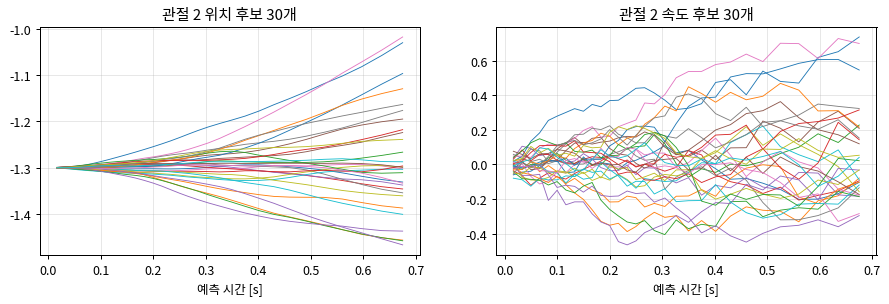

In [3]:
def integrate_acc(q0, qd0, acc, dts):
    # acc: [B, H, 7], dts: [H] -> q, qd: [B, H, 7]
    B, H, D = acc.shape
    q = np.empty_like(acc); qd = np.empty_like(acc)
    qc, qdc = np.broadcast_to(q0, (B, D)).copy(), np.broadcast_to(qd0, (B, D)).copy()
    for k in range(H):
        qc = qc + qdc * dts[k] + 0.5 * acc[:, k] * dts[k] ** 2
        qdc = qdc + acc[:, k] * dts[k]
        q[:, k], qd[:, k] = qc, qdc
    return q, qd

from toy import sample_noise
q0 = np.array([0.0, -1.3, 0.0, -2.5, 0.0, 1.0, 0.0])        # franka.yml retract_config 앞 7개
acc = sample_noise(400, 30, 7, seed=0) * np.sqrt(0.05) * 10  # 예시용 가속도 후보 [400,30,7]
q, qd = integrate_acc(q0, np.zeros(7), acc, dt_array(1 / 60))
print('act_seq', acc.shape, '-> q', q.shape, ', qd', qd.shape)
print('horizon 끝에서 관절 위치 퍼짐(표준편차, rad):', q[:, -1].std(0).round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
t = np.cumsum(dt_array(1 / 60))
for i in range(30):
    axs[0].plot(t, q[i, :, 1], lw=0.7); axs[1].plot(t, qd[i, :, 1], lw=0.7)
axs[0].set_title('관절 2 위치 후보 30개'); axs[1].set_title('관절 2 속도 후보 30개')
for a in axs: a.set_xlabel('예측 시간 [s]')
plt.show()

## 3. FK와 충돌 구 — cuRobo로 직접 보기

관절 위치가 정해지면 FK로 EE 자세와 **충돌 구 중심**을 계산한다. Franka mesh는 구들로 근사되어 있다 (`content/configs/robot/spheres/franka_mesh.yml`). 구 반지름에는 `collision_sphere_buffer`가 더해진다. 기본값은 0.004 m이고, 이 프로젝트는 `hand_experiment.py:90`에서 0.02 m로 덮어쓴다.

아래 셀은 cuRobo `CudaRobotModel`로 retract 자세의 구를 계산한다. 배열에는 구가 65개 있지만, 그중 반지름이 0 이하인 것은 비활성 슬롯이다(부착 물체용 등). 그래서 활성 구는 61개다. 실험 로그도 `spheres[:,3] > 0`으로 걸러 61개를 쓴다 (`hand_experiment.py:320`).

구 배열 65개, 활성(r>0) 61개
buffer 0.02 - 0.004 반지름 차이: [0.016] m
링크별 활성 구 수: {'panda_link0': 2, 'panda_link1': 4, 'panda_link2': 4, 'panda_link3': 4, 'panda_link4': 4, 'panda_link5': 13, 'panda_link6': 3, 'panda_link7': 5, 'panda_hand': 18, 'panda_leftfinger': 2, 'panda_rightfinger': 2}
로그 robot-spheres.npz: (472, 61, 4) | 반지름 집합이 같은가: True


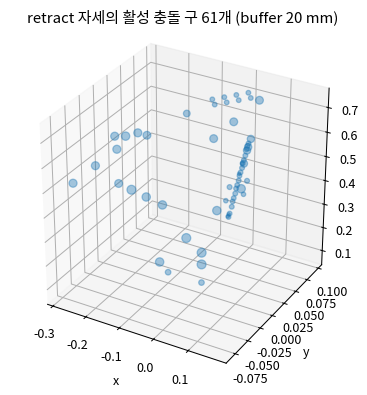

In [4]:
if HAS_CUROBO:
    from curobo.cuda_robot_model.cuda_robot_model import CudaRobotModel, CudaRobotModelConfig
    from curobo.types.base import TensorDeviceType
    from curobo.util_file import load_yaml as cu_load_yaml, join_path, get_robot_configs_path
    ta = TensorDeviceType()

    def franka_model(buffer):
        cfg = cu_load_yaml(join_path(get_robot_configs_path(), 'franka.yml'))['robot_cfg']
        cfg['kinematics']['collision_sphere_buffer'] = buffer
        return CudaRobotModel(CudaRobotModelConfig.from_data_dict(cfg['kinematics'], tensor_args=ta)), cfg

    km20, rcfg = franka_model(0.02)
    km04, _ = franka_model(0.004)
    q_ret = ta.to_device([rcfg['kinematics']['cspace']['retract_config'][:7]])
    sph20 = km20.get_state(q_ret).link_spheres_tensor.reshape(-1, 4).cpu().numpy()
    sph04 = km04.get_state(q_ret).link_spheres_tensor.reshape(-1, 4).cpu().numpy()
    active = sph20[:, 3] > 0
    print('구 배열 %d개, 활성(r>0) %d개' % (len(sph20), active.sum()))
    print('buffer 0.02 - 0.004 반지름 차이: %s m' % np.unique((sph20[active, 3] - sph04[active, 3]).round(6)))

    # 링크별 구 개수
    kc = km20.kinematics_config
    idx2name = {v: k for k, v in kc.link_name_to_idx_map.items()}
    link_of = [idx2name[int(i)] for i in kc.link_sphere_idx_map.cpu().numpy()]
    from collections import Counter
    cnt = Counter(l for l, a in zip(link_of, active) if a)
    print('링크별 활성 구 수:', dict(cnt))

    # 로그의 반지름(buffer 포함)과 비교
    logged_sph = np.load(EVIDENCE / 'R' / 'robot-spheres.npz')['spheres']
    print('로그 robot-spheres.npz:', logged_sph.shape, '| 반지름 집합이 같은가:',
          np.allclose(np.sort(logged_sph[0, :, 3]), np.sort(sph20[active, 3])))

    fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection='3d')
    s = sph20[active]
    ax.scatter(s[:, 0], s[:, 1], s[:, 2], s=(s[:, 3] * 400) ** 2 / 20, alpha=0.4)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z'); ax.set_title('retract 자세의 활성 충돌 구 61개 (buffer 20 mm)')
    ax.set_box_aspect((1, 1, 1)); plt.show()
else:
    print('cuRobo/CUDA가 없어 건너뜀')

**거리 기준 주의 (노션 3절 callout):** 로그의 `original_surface_clearance_m`은 "관측 ROI 점 ↔ **buffer 20 mm 포함** 구 표면" 거리다. 그래서 buffer를 뺀 근사 구 표면 기준(README 표의 "버퍼 제외")과 정확히 20 mm 차이가 난다. 실제 Franka mesh 표면까지의 거리는 어느 쪽과도 다르다.

## 4. Isaac Sim 없이 cuRobo MPC rollout 들여다보기

cuRobo `MpcSolver`는 Isaac Sim 없이도 만들 수 있다. 여기서는 다음 순서로 실험 장면을 흉내 낸다.
- **충돌 세계:** nvblox 대신 PRIMITIVE 세계에 손 크기 cuboid 하나를 둔다(손 ROI 중심 근처).
- **시작 상태:** R 실험 로그(`evidence/R/metrics.jsonl`)에서 손에 다가가던 step 150의 실제 관절 위치·속도를 쓴다.
- **목표:** Target B(`scene.json`).
- **설정:** `use_cuda_graph=False`. 내부 함수를 직접 호출하려고 끈 것이고, 실험에서는 `True`다.

그다음 optimizer의 rollout 함수를 직접 호출해 shape와 비용 항을 확인한다.

In [5]:
if HAS_CUROBO:
    from curobo.geom.types import WorldConfig, Cuboid
    from curobo.types.math import Pose
    from curobo.types.state import JointState
    from curobo.rollout.rollout_base import Goal
    from curobo.rollout.arm_base import ArmBase
    from curobo.wrap.reacher.mpc import MpcSolver, MpcSolverConfig

    scene_cfg = json.loads((REPO / 'experiment' / 'scene.json').read_text())
    hand_box = Cuboid(name='hand_box', pose=[0.55, 0.0, 0.42, 1, 0, 0, 0], dims=[0.03, 0.12, 0.16])
    t0 = time.time()
    mpc = MpcSolver(MpcSolverConfig.load_from_robot_config(
        rcfg, WorldConfig(cuboid=[hand_box]), use_cuda_graph=False, use_mppi=True, use_lbfgs=False, use_es=False,
        store_rollouts=True, step_dt=1 / 60, self_collision_check=True))
    print('MpcSolver 생성 %.1fs' % (time.time() - t0))

    rows = read_jsonl(EVIDENCE / 'R' / 'metrics.jsonl')
    r150 = next(r for r in rows if r['step'] == 150)
    print('R step 150: goal_index=%d, EE=%s, 로그 clearance(buffer 포함)=%.1f mm' % (
        r150['goal_index'], np.round(r150['ee_position'], 3), 1000 * r150['original_surface_clearance_m']))
    js = JointState.from_position(ta.to_device([r150['actual_q'][:7]]), joint_names=mpc.joint_names)
    js.velocity[:] = ta.to_device([r150['actual_velocity']])
    goal = Goal(current_state=js, goal_state=js, goal_pose=Pose.from_list(scene_cfg['goals_wxyz'][1], ta))
    gb = mpc.setup_solve_single(goal, 1); mpc.update_goal(gb)
    for _ in range(3):                      # 몇 번 풀어 평균 행동열을 현재 상태에 맞춘다
        res = mpc.step(js, max_attempts=1)
    print('mpc.step 결과 js_action:', tuple(res.js_action.position.shape), '| feasible:', res.metrics.feasible.cpu().tolist())
else:
    print('cuRobo/CUDA가 없어 건너뜀')

MpcSolver 생성 0.9s
R step 150: goal_index=1, EE=[ 0.521 -0.361  0.405], 로그 clearance(buffer 포함)=146.7 mm
mpc.step 결과 js_action: (1, 9) | feasible: [[True]]


optimizer: ParallelMPPI | rollout: ArmReacher
act_seq           (400, 30, 7)
관절 위치 예측     (400, 30, 7)
EE 위치 예측       (400, 30, 3)
충돌 구 예측       (400, 30, 65, 4) (마지막 축 = x, y, z, r)
costs             (400, 30)
traj_dt 합        0.675 s

항별 할인 합 (후보 400개 중앙값 / 최대):
  bound                중앙값    1284.04   최대      2007.86
  stop                 중앙값    8477.71   최대      9077.44
  self_collision       중앙값       0.00   최대         0.00
  env_collision        중앙값   34425.19   최대    598856.45
  pose 목표 등 (나머지)      중앙값  117604.14   최대    119971.31

환경(손 cuboid) 충돌 비용이 생긴 후보: 400 / 400
총비용 최저 후보 #248: 충돌비용 있음
구-박스 간격: 첫 예측 시점 최소 82.7 mm, horizon 전체 최소 -61.9 mm (η=25 mm)


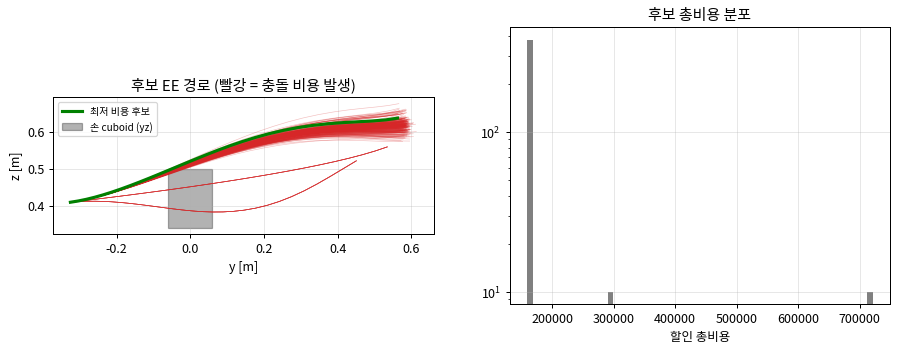

In [6]:
if HAS_CUROBO:
    opt = mpc.solver.optimizers[0]
    ro = opt.rollout_fn
    print('optimizer:', type(opt).__name__, '| rollout:', type(ro).__name__)
    act = opt.sample_actions(opt.mean_action)                 # [400, 30, 7]
    traj = ro.rollout_fn(act)
    st = traj.state
    print('act_seq          ', tuple(act.shape))
    print('관절 위치 예측    ', tuple(st.state_seq.position.shape))
    print('EE 위치 예측      ', tuple(st.ee_pos_seq.shape))
    print('충돌 구 예측      ', tuple(st.robot_spheres.shape), '(마지막 축 = x, y, z, r)')
    print('costs            ', tuple(traj.costs.shape))
    print('traj_dt 합        %.3f s' % float(ro.dynamics_model.traj_dt.sum()))

    # 비용 항 분해: ArmBase.cost_fn 순서 = bound, stop, self collision, 환경 collision (+ ArmReacher가 pose 목표 추가)
    terms = ArmBase.cost_fn(ro, st, act, return_list=True)
    names = ['bound', 'stop', 'self_collision', 'env_collision']
    parts = {n: c.detach().cpu().numpy() for n, c in zip(names, terms)}
    total = traj.costs.cpu().numpy()
    parts['pose 목표 등 (나머지)'] = total - sum(parts.values())
    gamma_seq = 0.98 ** np.arange(30)
    print('\n항별 할인 합 (후보 400개 중앙값 / 최대):')
    for n, c in parts.items():
        Sx = (c * gamma_seq).sum(1)
        print('  %-20s 중앙값 %10.2f   최대 %12.2f' % (n, np.median(Sx), Sx.max()))
    S_tot = (total * gamma_seq).sum(1)
    hit = (parts['env_collision'] > 0).any(1)
    print('\n환경(손 cuboid) 충돌 비용이 생긴 후보: %d / 400' % hit.sum())
    print('총비용 최저 후보 #%d: 충돌비용 %s' % (S_tot.argmin(), '있음' if hit[S_tot.argmin()] else '없음'))

    # buffer 포함 구 표면 ↔ 손 cuboid(축 정렬) 간격: 현재 시점과 horizon 전체 최소
    s = st.robot_spheres.cpu().numpy()
    lo = np.array(hand_box.pose[:3]) - np.array(hand_box.dims) / 2
    hi = np.array(hand_box.pose[:3]) + np.array(hand_box.dims) / 2
    gap = np.linalg.norm(np.maximum(0, np.maximum(lo - s[..., :3], s[..., :3] - hi)), axis=-1) - s[..., 3]
    gap[s[..., 3] <= 0] = np.inf
    print('구-박스 간격: 첫 예측 시점 최소 %.1f mm, horizon 전체 최소 %.1f mm (η=25 mm)' % (
        1000 * gap[:, 0].min(), 1000 * gap.min()))

    ee = st.ee_pos_seq.cpu().numpy()
    order = np.argsort(S_tot)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for i in order[::-1][:300]:
        c = 'tab:red' if hit[i] else 'tab:blue'
        axs[0].plot(ee[i, :, 1], ee[i, :, 2], color=c, lw=0.5, alpha=0.3)
    axs[0].plot(ee[order[0], :, 1], ee[order[0], :, 2], 'g-', lw=2.5, label='최저 비용 후보')
    axs[0].add_patch(plt.Rectangle((-0.06, 0.34), 0.12, 0.16, color='k', alpha=0.3, label='손 cuboid (yz)'))
    axs[0].set_xlabel('y [m]'); axs[0].set_ylabel('z [m]'); axs[0].legend(fontsize=8)
    axs[0].set_title('후보 EE 경로 (빨강 = 충돌 비용 발생)'); axs[0].set_aspect('equal')
    axs[1].hist(S_tot, bins=60, color='gray'); axs[1].set_yscale('log'); axs[1].set_xlabel('할인 총비용')
    axs[1].set_title('후보 총비용 분포')
    plt.show()
else:
    print('cuRobo/CUDA가 없어 건너뜀')

**확인한 것**
- 입력 `[400, 30, 7]` → 관절 상태 `[400, 30, 7]` → 구 `[400, 30, 65, 4]` → 비용 `[400, 30]`. 노션 U3 표의 흐름이 그대로 나온다.
- 현재 시점에는 박스와 떨어져 있어도, B로 가는 후보는 0.675 s 예측 안에서 모두 박스 근처를 지나간다. 그래서 후보 400개 **전부**에 환경 충돌 비용이 붙고, 최저 비용 후보도 충돌 비용을 안고 있다. 02 노트북 6절의 "모든 후보가 비싸면 덜 나쁜 후보"가 실제 Franka 장면에서 나타난 것이다. 이 장면에서는 pose 목표 항이 충돌 항보다 커서, 두 항의 절충으로 후보가 정해진다.
- 비용 항마다 weight가 다르지만, 실제로 어떤 항이 큰지는 **오차의 크기·활성 구 수·시점 누적**에 달려 있다. weight만 보고 행동을 단정할 수 없다는 노션의 "해석 주의"를 숫자로 확인할 수 있다.
- 이 장면은 cuboid 근사다. 실험의 nvblox 지도·손 패치와는 다르므로 정량값은 비교하지 않는다.

05 노트북은 이 `cost_fn`에 손 패치 비용을 덧붙이는 `TargetCostChannel` 훅을 다룬다. 07 노트북은 같은 solver를 Isaac Sim 루프에 넣는다.

## 5. activation distance η 비용식

cuRobo 충돌 커널(`curobolib/cpp/sphere_obb_kernel.cu`의 `scale_eta_metric`)은 먼저 구 반지름에 η를 더한다(노션 기록 `sphere_cache.w += eta`). 그래서 커널 안의 거리값은 $x = \eta - c$이다($c$ = buffer 포함 구 표면과 장애물 사이 간격).

$$
C(c) = w\begin{cases}0 & c \ge \eta\\[2pt] \dfrac{(\eta-c)^2}{2\eta} & 0\le c<\eta\\[6pt] (\eta-c)-\dfrac{\eta}{2} & c<0\end{cases}
$$

$c=0$에서 두 식의 값($\eta/2$)과 기울기(−1)가 이어진다. 그래서 겹치기 전부터 부드럽게 밀어내고, 겹친 뒤에는 일정한 기울기로 밀어낸다. 아래에서 노션 숫자 표를 재현하고 최종 HIGH(p=1) 73.52 mm 열을 추가한다.

  652| 
  653| 
  654|       if(SCALE_METRIC)
  655|       {
  656| 
  657|         if (sph_dist > 0)
  658|         {
  659| 
  660|           if (sph_dist > eta)
  661|           {
  662|             sum_pt.w = sph_dist - 0.5 * eta;
  663|           }
  664|           else if (sph_dist <= eta)
  665|           {
  666|             sum_pt.w = (0.5 / eta) * (sph_dist) * (sph_dist);
  667|             const float scale = (1.0 / eta) * (sph_dist);
  668|             sum_pt.x = scale * sum_pt.x;
  669|             sum_pt.y = scale * sum_pt.y;
  670|             sum_pt.z = scale * sum_pt.z;
  671|           }
  672| 
  673|         }
  674|         else
  675|         {
  676|           sum_pt.x = 0.0;
  677|           sum_pt.y = 0.0;
  678|           sum_pt.z = 0.0;
  679|           sum_pt.w = 0.0;
  680| 

간격 c [mm] | LOW 25 mm | HIGH p=0.5 42.87 mm | HIGH p=1 73.52 mm
        40 |                  0 |                 10 |                764
        20 |                 50 |             

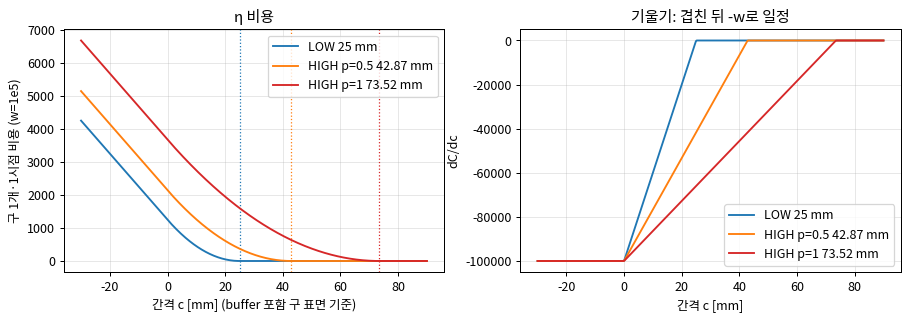

In [7]:
src = CUROBO / 'src/curobo/curobolib/cpp/sphere_obb_kernel.cu'
show_code(src, 652, 680)

etas = {'LOW 25 mm': 0.025, 'HIGH p=0.5 42.87 mm': eta_policy(2.3, 0.5), 'HIGH p=1 73.52 mm': eta_policy(2.3, 1.0)}
gaps_mm = np.array([40, 20, 10, 0, -10])
print('\n간격 c [mm] | ' + ' | '.join(etas))
for g in gaps_mm:
    print('%10d | ' % g + ' | '.join('%18.0f' % eta_cost(g / 1000, e, 1e5) for e in etas.values()))

c = np.linspace(-0.03, 0.09, 600)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for (lab, e), col in zip(etas.items(), ['tab:blue', 'tab:orange', 'tab:red']):
    C = eta_cost(c, e, 1e5)
    axs[0].plot(c * 1000, C, color=col, label=lab); axs[0].axvline(e * 1000, color=col, ls=':', lw=1)
    axs[1].plot(c * 1000, np.gradient(C, c), color=col, label=lab)
axs[0].set_xlabel('간격 c [mm] (buffer 포함 구 표면 기준)'); axs[0].set_ylabel('구 1개·1시점 비용 (w=1e5)'); axs[0].legend(); axs[0].set_title('η 비용')
axs[1].set_xlabel('간격 c [mm]'); axs[1].set_ylabel('dC/dc'); axs[1].set_title('기울기: 겹친 뒤 -w로 일정'); axs[1].legend()
plt.show()

- η가 커지면 더 먼 거리부터 비용이 생기고, 같은 간격에서 비용도 크다. 겹친 뒤의 기울기는 η와 무관하게 $-w$로 같다.
- 이 값은 **구 하나·시점 하나**의 비용이다. 후보의 총비용은 61개 구 × 30 시점(γ 할인) × 손 패치 최대 64개에 걸쳐 합산된다. 그래서 구 하나의 비용 50만 보고 회피·통과를 단정할 수 없다(노션 6절 정정).
- η는 비용이 켜지는 거리일 뿐 보장 이격이 아니다. 실험 결과는 06 노트북에서 본다(HIGH p=1의 버퍼 포함 최소 이격 +40.4 mm < η 73.5 mm).

## 6. 비용 구성 — yml에서 직접 읽기

In [8]:
cost_cfg = load_yaml(CUROBO / 'src/curobo/content/configs/task/particle_mpc.yml')['cost']
show = {
    'pose_cfg': ['weight', 'terminal', 'run_weight'],
    'bound_cfg': ['weight', 'activation_distance', 'smooth_weight'],
    'primitive_collision_cfg': ['weight', 'activation_distance', 'use_sweep', 'sweep_steps'],
    'self_collision_cfg': ['weight'],
    'stop_cfg': ['weight', 'max_nlimit'],
}
for k, keys in show.items():
    print('%-24s ' % k + ', '.join(f'{kk}={cost_cfg[k][kk]}' for kk in keys))
print('\nMPC 상태 필터:', load_yaml(CUROBO / 'src/curobo/content/configs/task/particle_mpc.yml')['model']['state_filter_cfg'])

pose_cfg                 weight=[60, 300.0, 20, 20], terminal=True, run_weight=1.0
bound_cfg                weight=[5000.0, 5000.0, 5000.0, 0.0], activation_distance=[0.1, 0.1, 0.1, 0.1], smooth_weight=[0.0, 50.0, 0.0, 0.0]
primitive_collision_cfg  weight=100000.0, activation_distance=0.025, use_sweep=True, sweep_steps=4
self_collision_cfg       weight=50000.0
stop_cfg                 weight=100.0, max_nlimit=0.25

MPC 상태 필터: {'filter_coeff': {'position': 0.1, 'velocity': 0.1, 'acceleration': 0.0}, 'enable': True}


| 비용 | 역할 | 노트 |
|---|---|---|
| pose `[60, 300, 20, 20]` | EE 위치·자세 목표 추종 | 4개 값은 각각 회전/위치 가중치와 그 run-time 가중치 계열. 해석은 `PoseCost` 구현 기준으로 확인 |
| bound 5000 | 관절 위치·속도·가속도 한계 근처 | `activation_distance` 0.1 (한계의 비율) |
| stop 100 | horizon 안에 멈출 수 없는 고속 억제 | `max_nlimit` 0.25 |
| self collision 50000 | 로봇 구끼리 충돌 | |
| primitive collision 100000, η 0.025 | 환경(nvblox/cuboid) 충돌 | `use_sweep` 4분할: 시점 사이 구간 검사 |
| (프로젝트 추가) 손 패치 비용 100000, η 25/73.5 mm | 손 ROI 관측점 근접 | 05 노트북, `C_total = C_existing + α·C_hand` |

상태 필터(`position: 0.1, velocity: 0.1`)는 측정 상태를 그대로 optimizer에 넣지 않고 섞어서 넣는다. 06 노트북에서 "필터 출력 − 실제" 차이가 최대 약 0.036 rad인 것을 로그로 확인한다.

## 정정 포인트

| 이전 이해 | 정정 |
|---|---|
| horizon = 30 × 0.02 = 0.6 s | 가변 dt: base 0.02면 0.75 s, 최종 실험(base 1/60)은 **0.675 s** |
| MPC dt 0.02 vs physics 1/60 불일치 | 최종 replay는 `--model-dt 1/60`으로 일치 |
| 충돌 구 = 65개 | 배열 65칸 중 활성(r>0) **61개** |
| `dynamics_model` = 동역학 모델 | 가속도 적분 + FK의 기구학 예측. 질량·관성 없음 |
| η = 최소 이격 보장 | 비용이 켜지는 거리. 겹친 뒤 기울기는 η와 무관 |

## 복습 질문

<details><summary>1. base_dt를 1/60로 바꾸면 horizon이 0.75 s에서 0.675 s로 줄어드는 계산을 설명하면?</summary>
앞 15칸: 15×1/60 = 0.25 s. 뒤 15칸: 1/60에서 0.04까지 선형 15점의 합 = 15×(0.0167+0.04)/2 ≈ 0.425 s. 합 0.675 s. max_dt=0.04는 그대로라서 뒤쪽만 덜 줄어든다.
</details>

<details><summary>2. 같은 간격 c=10 mm에서 η=25 mm와 73.52 mm의 구 1개 비용(w=1e5)은?</summary>
(η−c)²/(2η)×w: 25 mm → 15²/50 mm = 4.5 mm → 450. 73.52 mm → 63.52²/147.03 mm ≈ 27.4 mm → 약 2744.
</details>

<details><summary>3. 로그 clearance가 −29.5 mm라는 것은 실제 로봇과 손이 29.5 mm 겹쳤다는 뜻인가?</summary>
아니다. buffer 20 mm가 포함된 근사 구와 카메라가 본 손 표면 점 사이 값이다. buffer를 빼면 −9.5 mm이고, 실제 mesh와 손 전체(가려진 뒷면 포함) 사이 거리는 측정하지 않았다.
</details>

<details><summary>4. rollout 비용에서 env_collision 항이 0인데 로봇이 장애물과 겹칠 수 있는 경우는?</summary>
지도가 그 위치를 모르는 경우다(미관측 ESDF → 비용 0). 04 노트북의 Baseline R 실패 원인이 이것이다. 또 sweep이 꺼져 있으면 시점 사이 통과도 놓칠 수 있다.
</details>

**다음:** [04 · U4 nvblox / ESDF](04_U4_nvblox_esdf.ipynb) — 환경 충돌 비용의 거리값이 어디서 오는지, 미관측이 왜 비용 0이 되는지.